# RETAIL DEMAND & BASKET ANALYSIS

**Project 2 – Arrowstack Data Science Internship**

## 1. Business Problem

Retail businesses need to understand customer purchasing behaviour, product demand and relationships between products. This project analyses historical retail transactions to identify sales patterns, popular products and product combinations that customers frequently purchase together.

## 2. Dataset Description

The Online Retail dataset was obtained from the UCI Machine Learning Repository [1]. The original dataset contains **541,909 transaction records** from a UK-based online retailer, covering the period from December 2010 to December 2011.

For this project, the first **10,000 records** were loaded for analysis due to processing constraints. Following data cleaning, **9,658 records** remained for analysis.

The dataset contains all eight original features: InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID and Country. An additional feature, **Sales**, was created by multiplying Quantity by UnitPrice to calculate transaction-level sales revenue.

**Dataset:** `Online Retail.xlsx`

## 3. Project Objectives

- Assess and clean the retail transaction dataset.
- Perform data quality checks and develop a data dictionary.
- Analyse sales trends and product demand.
- Identify the most frequently purchased products.
- Apply market basket analysis to discover product associations.
- Generate evidence-based business insights and recommendations.

## 4. Primary Stakeholder

**Retail Operations Manager**

The analysis aims to support inventory planning, product bundling, cross-selling and promotional decisions by identifying purchasing patterns and product associations.

## 5. Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Mlxtend (Apriori and Association Rules)
- Jupyter Notebook

## 6. Project Workflow

1. Data acquisition and initial inspection.
2. Data dictionary development.
3. Data cleaning and quality assessment.
4. Exploratory Data Analysis (EDA).
5. Sales and product demand analysis.
6. Market basket analysis using Apriori.
7. Association rule evaluation using support, confidence and lift.
8. Business insights and recommendations.
9. Validation, limitations and documentation.

## 7. Expected Deliverables

- Cleaned retail transaction data.
- Data dictionary and quality assessment.
- EDA tables and visualisations.
- Frequent itemsets and association rules.
- Evidence-based business recommendations.
- Final project documentation.

## 8. Scope and Limitations

This project uses a 10,000-record sample from the original Online Retail dataset of 541,909 records. Although all eight original dataset features are retained, the analysis is based on only the first 10,000 records, covering the initial period of the dataset rather than the full retail year.

The sample may not fully represent the purchasing behaviour of all customers or the complete retail market. Missing CustomerID values were retained because customer identifiers are not essential for invoice-level product association analysis.

The analysis identifies historical purchasing patterns, sales trends and product associations but does not establish causation. Findings should therefore be treated as exploratory and validated using the full dataset before major business decisions are made.



In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


In [17]:
# Loading Dataset
# Pandas will be used to read the dataset and preprocess it.
# A sample of 10,000 records is loaded for efficient analysis.

df = pd.read_excel(
    r"C:\Users\janef\OneDrive\Desktop\Arrowstack_Internship\Online Retail.xlsx",
    nrows=10000
)

# Display dataset dimensions
print("Dataset Shape:", df.shape)

Dataset Shape: (10000, 8)


## Initial Data Inspection

The dataset was loaded into a Pandas DataFrame to examine its structure, dimensions, column names and sample records. This initial inspection helps understand the available variables and identify potential data quality issues before cleaning and analysis.

In [18]:
# Display the first five records
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [21]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

Dataset Shape: (10000, 8)


In [20]:
# Display dataset column names
df.columns.tolist()

['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country']

In [22]:
# Check data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    10000 non-null  object        
 1   StockCode    10000 non-null  object        
 2   Description  9958 non-null   object        
 3   Quantity     10000 non-null  int64         
 4   InvoiceDate  10000 non-null  datetime64[ns]
 5   UnitPrice    10000 non-null  float64       
 6   CustomerID   7709 non-null   float64       
 7   Country      10000 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 625.1+ KB


### Initial Data Quality Observations

The initial inspection identified missing values in two columns:

- **Description:** 42 missing values out of 10,000 records.
- **CustomerID:** 2,291 missing values out of 10,000 records.

These values were identified by comparing the non-null counts with the total number of records.

The remaining six columns contain no missing values. These issues will be investigated and addressed during the data cleaning stage.

In [23]:
# Statistical Summary
# Generating descriptive statistics for numerical and categorical columns.

df.describe(include='all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,10000.0,10000.0,9958,10000.000000,10000,10000.000000,7709.000000,10000
unique,512.0,2015.0,1981,NaN,NaN,NaN,NaN,15
top,536876.0,22632.0,HAND WARMER UNION JACK,NaN,NaN,NaN,NaN,United Kingdom
freq,593.0,63.0,59,NaN,NaN,NaN,NaN,9403
mean,NaN,NaN,NaN,7.828600,2010-12-03 05:58:26.346000128,3.837412,15615.462576,NaN
min,NaN,NaN,NaN,-9360.000000,2010-12-01 08:26:00,0.000000,12395.000000,NaN
25%,NaN,NaN,NaN,1.000000,2010-12-01 17:06:00,1.250000,14388.000000,NaN
50%,NaN,NaN,NaN,2.000000,2010-12-02 18:08:00,2.510000,15605.000000,NaN
75%,NaN,NaN,NaN,8.000000,2010-12-05 10:45:00,4.210000,17228.000000,NaN
max,NaN,NaN,NaN,2880.000000,2010-12-05 16:24:00,887.520000,18239.000000,NaN


In [24]:
# Missing Values
# Checking the number of missing values in each column.

df.isnull().sum()

InvoiceNo         0
StockCode         0
Description      42
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID     2291
Country           0
dtype: int64

In [25]:
# Duplicate Records
# Checking the dataset for duplicated rows.

print("Number of Duplicate Records:", df.duplicated().sum())

Number of Duplicate Records: 196


### Duplicate Records Observation

The duplicate check identified 196 duplicated records in the dataset.

Duplicate records may affect the accuracy of sales calculations and product association analysis if they are counted more than once.

These exact duplicate records will be removed during the data cleaning stage.

## Data Cleaning and Quality Checks

Data cleaning is performed to address missing values, duplicate records and invalid transaction entries. This helps improve the reliability and accuracy of the subsequent analysis.

In [26]:
# Remove duplicate records
df = df.drop_duplicates()

# Check the updated dataset shape
print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (9804, 8)


### Duplicate Removal

A total of 196 duplicate records were identified and removed from the dataset. The dataset now contains 9,804 records across 8 columns.

Removing exact duplicates helps prevent repeated transaction records from affecting the accuracy of the analysis.

In [27]:
# Check for invalid transaction values

print("Negative quantities:", (df['Quantity'] < 0).sum())

print("Zero or negative unit prices:", (df['UnitPrice'] <= 0).sum())

print(
    "Cancellation invoices:",
    df['InvoiceNo'].astype(str).str.startswith('C').sum()
)

Negative quantities: 130
Zero or negative unit prices: 46
Cancellation invoices: 100


### Invalid Transaction Observations

The data quality checks identified negative quantities, zero or negative unit prices and cancellation invoices.

- 130 records contain negative quantities.
- 46 records contain zero or negative unit prices.
- 100 records have invoice numbers beginning with "C".

Negative quantities and cancellation invoices may represent returned or cancelled transactions. These records will be excluded from the positive-sales and market basket analysis to avoid distorting product demand patterns. Records with invalid prices will also be excluded from sales calculations.

In [28]:
# Remove records with missing product descriptions
df = df.dropna(subset=['Description'])

# Keep only positive quantities and unit prices
df = df[
    (df['Quantity'] > 0) &
    (df['UnitPrice'] > 0)
]

# Exclude cancellation invoices
df = df[
    ~df['InvoiceNo'].astype(str).str.startswith('C')
]

# Check the cleaned dataset
print("Cleaned Dataset Shape:", df.shape)
print("\nRemaining Missing Values:")
print(df.isnull().sum())

Cleaned Dataset Shape: (9658, 8)

Remaining Missing Values:
InvoiceNo         0
StockCode         0
Description       0
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID     2246
Country           0
dtype: int64


### Data Cleaning Summary

The following cleaning steps were completed:

- Removed 196 duplicate records.
- Removed records with missing product descriptions.
- Excluded transactions with negative or zero quantities.
- Excluded transactions with zero or negative unit prices.
- Excluded cancellation invoices.

The cleaned dataset contains 9,658 records across 8 columns. A total of 2,246 CustomerID values remain missing. These have been retained because customer identifiers are not essential for invoice-level product association analysis.

In [29]:
# Display the cleaned dataset data types

data_dictionary = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.astype(str).values,
    'Description': [
        'Unique invoice or transaction number',
        'Product identification code',
        'Product name or description',
        'Number of units purchased',
        'Date and time of the transaction',
        'Price per unit',
        'Customer identification number',
        'Country where the customer is located'
    ]
})

display(data_dictionary)

,Column,Data Type,Description
0,InvoiceNo,object,Unique invoice or transaction number
1,StockCode,object,Product identification code
2,Description,object,Product name or description
3,Quantity,int64,Number of units purchased
4,InvoiceDate,datetime64[ns],Date and time of the transaction
5,UnitPrice,float64,Price per unit
6,CustomerID,float64,Customer identification number
7,Country,object,Country where the customer is located


### Data Dictionary

The data dictionary documents the meaning and data type of each variable in the dataset. It provides a clear reference for understanding the transaction records and supports reproducibility throughout the analysis.

## Exploratory Data Analysis (EDA)

In [30]:
# Calculate total sales for each transaction

df['Sales'] = df['Quantity'] * df['UnitPrice']

# Display key sales statistics

print("Total Transactions:", df['InvoiceNo'].nunique())
print("Unique Products:", df['StockCode'].nunique())
print("Total Quantity Sold:", df['Quantity'].sum())
print("Total Sales Revenue: £{:,.2f}".format(df['Sales'].sum()))
print("Number of Countries:", df['Country'].nunique())

Total Transactions: 424
Unique Products: 1990
Total Quantity Sold: 89731
Total Sales Revenue: £183,529.13
Number of Countries: 15


### Key Sales Metrics

The cleaned dataset contains 424 unique transactions involving 1,990 different products across 15 countries.

A total of 89,731 units were sold, generating £183,529.13 in sales revenue.

These figures provide an overview of retail activity within the analysed sample. They should not be interpreted as totals for the complete Online Retail dataset.

In [31]:
# Identify the 10 best-selling products by quantity

top_products = (
    df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Best-Selling Products:")
display(top_products)

Top 10 Best-Selling Products:


Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     3409
ASSORTED COLOUR T-LIGHT HOLDER        1842
RED  HARMONICA IN BOX                 1660
ASSORTED INCENSE PACK                 1440
WHITE HANGING HEART T-LIGHT HOLDER    1009
PACK OF 72 RETROSPOT CAKE CASES        975
ASSORTED COLOUR BIRD ORNAMENT          904
RED WOOLLY HOTTIE WHITE HEART.         829
BROCADE RING PURSE                     798
PACK OF 12 LONDON TISSUES              729
Name: Quantity, dtype: int64

### Top 10 Best-Selling Products

The analysis identifies the 10 products with the highest total quantities sold.

WORLD WAR 2 GLIDERS ASSTD DESIGNS ranked first with 3,409 units sold, followed by ASSORTED COLOUR T-LIGHT HOLDER with 1,842 units and RED HARMONICA IN BOX with 1,660 units.

These results highlight the most popular products in the analysed sample and can help the retail operations team prioritise stock replenishment and inventory planning.

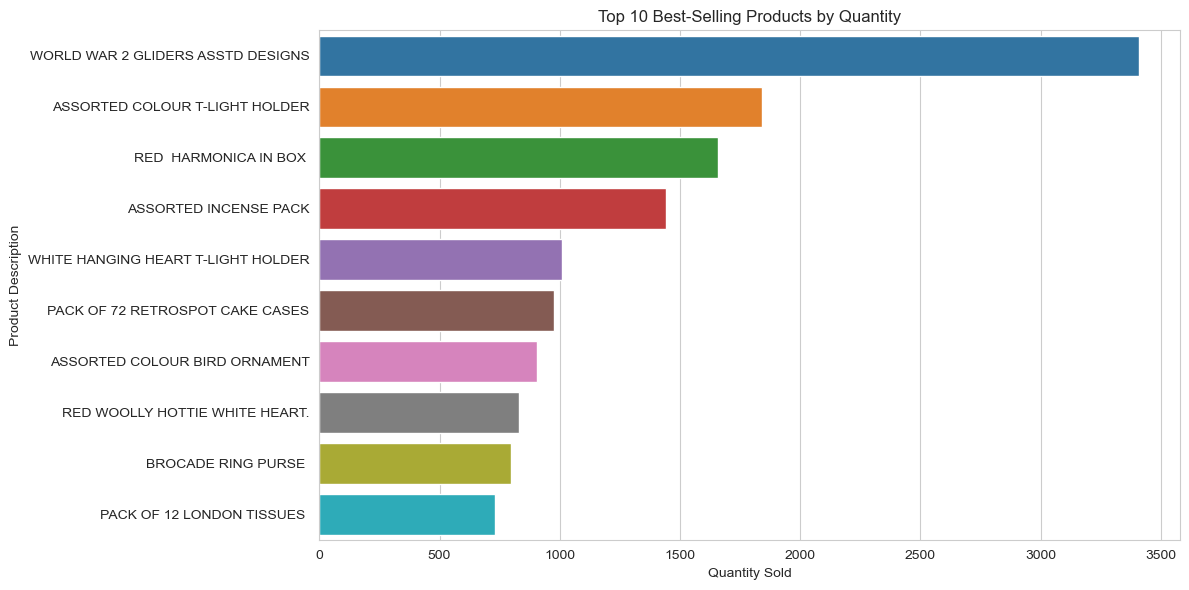

In [32]:
# Visualise the top 10 best-selling products

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title('Top 10 Best-Selling Products by Quantity')
plt.xlabel('Quantity Sold')
plt.ylabel('Product Description')
plt.tight_layout()
plt.show()

### Interpretation of Best-Selling Products Chart

The bar chart shows that WORLD WAR 2 GLIDERS ASSTD DESIGNS is the best-selling product, with approximately 3,409 units sold, slightly below 3,500.

ASSORTED COLOUR T-LIGHT HOLDER ranks second, with approximately 1,842 units sold, close to 2,000. RED HARMONICA IN BOX ranks third, with 1,660 units sold, slightly above 1,500.

The chart highlights a noticeable difference in demand between the leading product and the other top-selling products.

**Business Insight:** The retailer could prioritise stock monitoring and replenishment for these high-demand products to reduce the risk of stock shortages.

In [33]:
# Analyse total sales revenue by country

country_sales = (
    df.groupby('Country')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("Sales Revenue by Country:")
display(country_sales)

Sales Revenue by Country:


Country
United Kingdom    167651.80
Germany             3449.05
EIRE                3154.73
France              2808.16
Norway              1919.14
Lithuania           1598.06
Spain                620.00
Italy                427.80
Australia            358.25
Belgium              346.10
Japan                320.08
Switzerland          303.40
Poland               248.16
Netherlands          192.60
Portugal             131.80
Name: Sales, dtype: float64

### Sales Revenue by Country: Key Findings

The analysis shows that the United Kingdom generated the highest sales revenue, with £167,651.80. Germany ranked second with £3,449.05, followed by EIRE with £3,154.73 and France with £2,808.16.

The United Kingdom accounts for the largest share of revenue in the analysed sample, indicating a strong concentration of sales in the domestic market.

**Business Insight:** The retailer should maintain reliable stock availability in the UK market while exploring opportunities to increase sales in other countries.

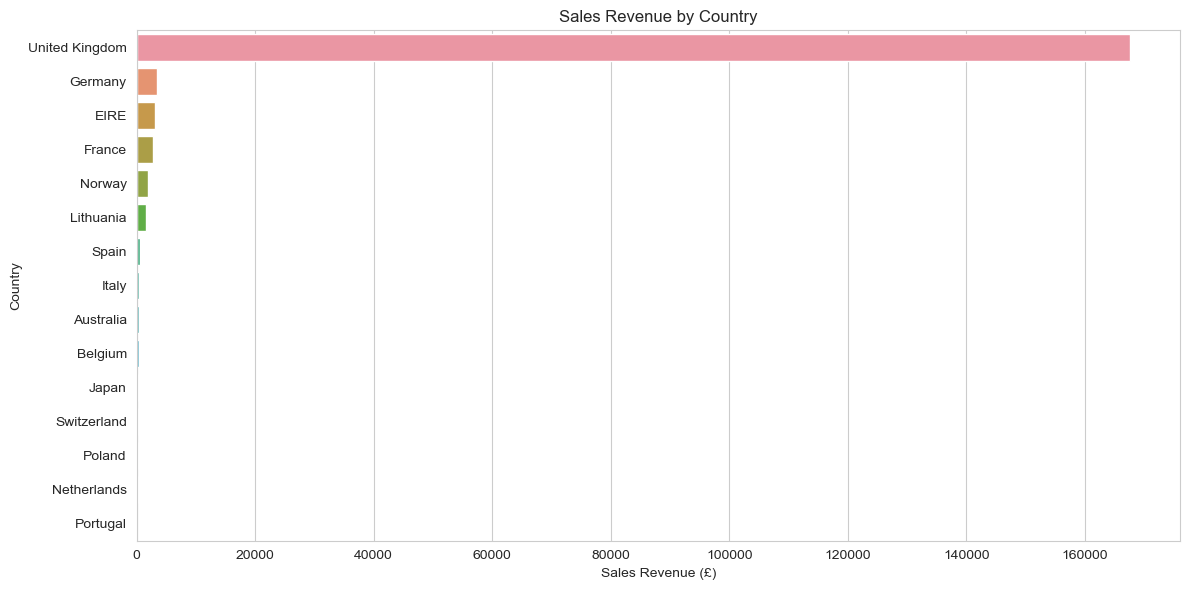

In [34]:
# Visualise sales revenue by country

plt.figure(figsize=(12, 6))

sns.barplot(
    x=country_sales.values,
    y=country_sales.index
)

plt.title('Sales Revenue by Country')
plt.xlabel('Sales Revenue (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

### Interpretation of Sales Revenue by Country Chart

The bar chart shows that the United Kingdom generated the highest sales revenue, with approximately £167,652.

Germany ranked second with approximately £3,449, followed by EIRE with approximately £3,155 and France with approximately £2,808.

The remaining countries generated considerably lower revenue, with each contributing less than £2,000.

The results show that sales revenue is heavily concentrated in the United Kingdom within the analysed sample.

**Business Recommendation:** The retailer should prioritise stock availability in the UK while exploring opportunities to grow sales in international markets.

## Daily Sales Trend Analysis

In [35]:
# Analyse daily sales revenue

daily_sales = (
    df.groupby(df['InvoiceDate'].dt.date)['Sales']
    .sum()
)

print("Daily Sales Revenue:")
display(daily_sales)

Daily Sales Revenue:


InvoiceDate
2010-12-01    58776.79
2010-12-02    47629.42
2010-12-03    46898.63
2010-12-05    30224.29
Name: Sales, dtype: float64

### Daily Sales Revenue Analysis

Daily sales revenue was calculated by grouping transactions according to invoice date and summing the sales values.

The results show that 1 December 2010 recorded the highest sales revenue of £58,776.79. Sales decreased to £47,629.42 on 2 December and £46,898.63 on 3 December. On 5 December, sales revenue was £30,224.29.

These results provide an overview of daily sales activity within the analysed sample.

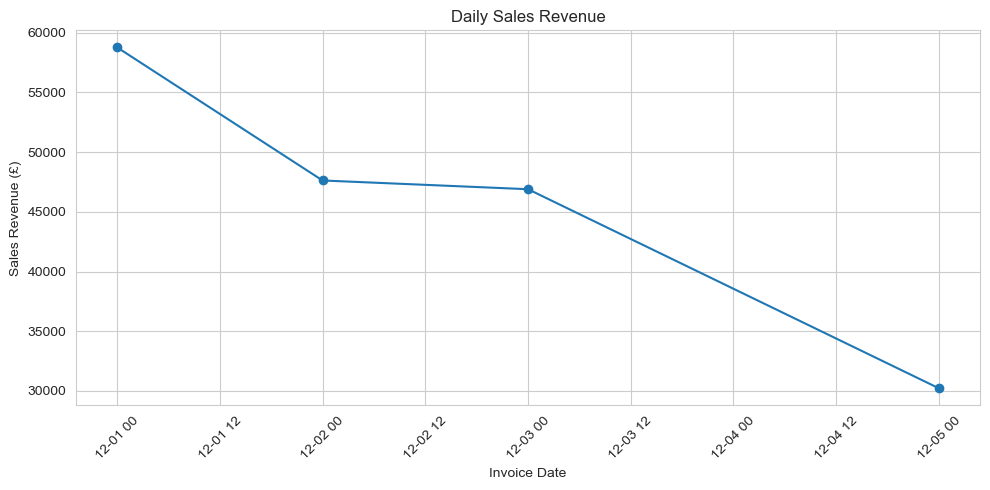

In [36]:
# Visualise daily sales revenue

plt.figure(figsize=(10, 5))

daily_sales.plot(kind='line', marker='o')

plt.title('Daily Sales Revenue')
plt.xlabel('Invoice Date')
plt.ylabel('Sales Revenue (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation of Daily Sales Revenue Chart

The line chart shows changes in daily sales revenue across the analysed dates.

1 December 2010 recorded the highest sales revenue at approximately £58,777, just below £60,000.

Sales revenue decreased on 2 December and 3 December, before falling further to £30,224 on 5 December 2010.

The chart highlights a downward trend in daily sales revenue across the dates represented in the sample.

## Market Basket Analysis

In [37]:
# Prepare transaction data for market basket analysis

basket_data = df[
    (df['Quantity'] > 0) &
    (df['Description'].notna())
].copy()

# Remove extra spaces from product descriptions
basket_data['Description'] = basket_data['Description'].str.strip()

# Create an invoice-by-product transaction table
basket = pd.crosstab(
    basket_data['InvoiceNo'],
    basket_data['Description']
)

# Convert quantities into binary values (1 = purchased, 0 = not purchased)
basket = (basket > 0).astype(int)

print("Basket Shape:", basket.shape)
display(basket.head())

Basket Shape: (424, 1967)


Description  10 COLOUR SPACEBOY PEN  12 COLOURED PARTY BALLOONS  \
InvoiceNo                                                         
536365                            0                           0   
536366                            0                           0   
536367                            0                           0   
536368                            0                           0   
536369                            0                           0   

Description  12 DAISY PEGS IN WOOD BOX  12 IVORY ROSE PEG PLACE SETTINGS  \
InvoiceNo                                                                  
536365                               0                                 0   
536366                               0                                 0   
536367                               0                                 0   
536368                               0                                 0   
536369                               0                                 0   

Description  12 MESSAGE CARDS WITH ENVELOPES  12 PENCIL SMALL TUBE WOODLAND  \
InvoiceNo                                                                     
536365                                     0                              0   
536366                                     0                              0   
536367                                     0                              0   
536368                                     0                              0   
536369                                     0                              0   

Description  12 PENCILS SMALL TUBE RED RETROSPOT  12 PENCILS SMALL TUBE SKULL  \
InvoiceNo                                                                       
536365                                         0                            0   
536366                                         0                            0   
536367                                         0                            0   
536368                                         0                            0   
536369                                         0                            0   

Description  12 PENCILS TALL TUBE POSY  12 PENCILS TALL TUBE RED RETROSPOT  \
InvoiceNo                                                                    
536365                               0                                   0   
536366                               0                                   0   
536367                               0                                   0   
536368                               0                                   0   
536369                               0                                   0   

Description  12 PENCILS TALL TUBE SKULLS  12 PENCILS TALL TUBE WOODLAND  \
InvoiceNo                                                                 
536365                                 0                              0   
536366                                 0                              0   
536367                                 0                              0   
536368                                 0                              0   
536369                                 0                              0   

Description  12 PINK ROSE PEG PLACE SETTINGS  12 RED ROSE PEG PLACE SETTINGS  \
InvoiceNo                                                                      
536365                                     0                               0   
536366                                     0                               0   
536367                                     0                               0   
536368                                     0                               0   
536369                                     0                               0   

Description  15CM CHRISTMAS GLASS BALL 20 LIGHTS  20 DOLLY PEGS RETROSPOT  \
InvoiceNo                                                                   
536365                                         0                        0   
536366    

### Transaction Basket Preparation

The transaction basket contains 424 unique invoices and 1,967 unique products.

Each row represents an invoice, while each column represents a product. The values are binary:

- 1 indicates that a product was included in the invoice.
- 0 indicates that a product was not included in the invoice.

This transaction matrix is prepared for market basket analysis using the Apriori algorithm.

##  Market Basket Analysis Using Apriori

Market Basket Analysis is used to identify products that customers frequently purchase together within the same transaction. The Apriori algorithm is applied to discover frequent product combinations and generate association rules.

The analysis uses support, confidence and lift to evaluate product relationships and identify potential opportunities for product bundling, cross-selling and promotional strategies.

In [39]:
# Install mlxtend for Market Basket Analysis

%pip install mlxtend

  Obtaining dependency information for mlxtend from https://files.pythonhosted.org/packages/61/b8/bda63104fa9e3c4e88bd158b664d21b66667fbee3eb35f737dd329dc26a3/mlxtend-0.25.0-py3-none-any.whl.metadata
  Obtaining dependency information for scipy>=1.16.3 from https://files.pythonhosted.org/packages/95/da/0d1df507cf574b3f224ccc3d45244c9a1d732c81dcb26b1e8a766ae271a8/scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata
     ---------------------------------------- 0.0/61.0 kB ? eta -:--:--
     ---------------------------------------- 61.0/61.0 kB 1.6 MB/s eta 0:00:00
  Obtaining dependency information for numpy>=2.3.5 from https://files.pythonhosted.org/packages/c5/31/7fc6239c12bce7e931463251cca4426c465e1876ba3cc785402ef4dd8f4e/numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for pandas>=2.3.3 from https://files.pythonhosted.org/packages/69/7c/8da507fc9ef7218aba9f6d66be872e3db09d3d4aa4b540ad27885ad89f02/pandas-3.1.1-cp311-cp311-win_amd64.whl.metadata
  Obtaining

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
conda-repo-cli 1.0.75 requires requests_mock, which is not installed.
gensim 4.3.0 requires FuzzyTM>=0.4.0, which is not installed.
tables 3.8.0 requires blosc2~=2.0.0, which is not installed.
tables 3.8.0 requires cython>=0.29.21, which is not installed.
botocore 1.29.76 requires python-dateutil<3.0.0,>=2.1, but you have python-dateutil 4.0.0 which is incompatible.
conda-repo-cli 1.0.75 requires clyent==1.2.1, but you have clyent 1.2.2 which is incompatible.
conda-repo-cli 1.0.75 requires python-dateutil==2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
conda-repo-cli 1.0.75 requires PyYAML==6.0.1, but you have pyyaml 6.0 which is incompatible.
numba 0.57.1 requires numpy<1.25,>=1.21, but you have numpy 2.4.6 which is incompatible.


In [40]:
from mlxtend.frequent_patterns import apriori, association_rules

print("Apriori library imported successfully!")

Apriori library imported successfully!


In [41]:
item_frequency = basket.sum().sort_values(ascending=False)
top_items = item_frequency.head(30).index
basket_top = basket[top_items]

print("Basket for Apriori:", basket_top.shape)

Basket for Apriori: (424, 30)


In [42]:
frequent_itemsets = apriori(
    basket_top,
    min_support=0.01,
    use_colnames=True,
    max_len=3
)

frequent_itemsets = frequent_itemsets.sort_values(
    'support',
    ascending=False
)

print("Number of frequent itemsets:", len(frequent_itemsets))
display(frequent_itemsets.head(15))

C:\Users\janef\anaconda3\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


Number of frequent itemsets: 1075


,support,itemsets
0,0.127358,(WHITE HANGING HEART T-LIGHT HOLDER)
1,0.127358,(HAND WARMER UNION JACK)
2,0.125000,(HAND WARMER OWL DESIGN)
3,0.113208,(HAND WARMER SCOTTY DOG DESIGN)
4,0.110849,(PAPER CHAIN KIT 50'S CHRISTMAS)
5,0.101415,(PAPER CHAIN KIT VINTAGE CHRISTMAS)
6,0.101415,(HAND WARMER BIRD DESIGN)
7,0.099057,(RED WOOLLY HOTTIE WHITE HEART.)
9,0.096698,(HAND WARMER RED RETROSPOT)
10,0.096698,(REGENCY CAKESTAND 3 TIER)


### Interpretation of Frequent Itemsets

The Apriori algorithm identified 1,075 frequent itemsets using a minimum support threshold of 1% and a maximum combination length of three products.

The results show that several products appeared frequently across the analysed transactions. WHITE HANGING HEART T-LIGHT HOLDER and HAND WARMER UNION JACK had the highest individual support, at approximately 12.74% each.

These findings help identify popular products and provide a foundation for examining relationships between products through association rules.

## Interpretation of Frequent Itemsets

The Apriori algorithm identified 1,075 frequent itemsets using a minimum support threshold of 1% and a maximum combination length of three products.

The results show that several products appeared frequently across the analysed transactions. WHITE HANGING HEART T-LIGHT HOLDER and HAND WARMER UNION JACK had the highest individual support, at approximately 12.74% each.

These findings help identify popular products and provide a foundation for examining relationships between products through association rules.

In [43]:
rules = association_rules(
    frequent_itemsets,
    metric='confidence',
    min_threshold=0.3
)

print("Number of association rules:", len(rules))

display(
    rules[
        ['antecedents', 'consequents', 'support', 'confidence', 'lift']
    ].sort_values('lift', ascending=False).head(10)
)

Number of association rules: 2298


,antecedents,consequents,support,confidence,lift
874,"(CHOCOLATE HOT WATER BOTTLE, REGENCY CAKESTAND...",(60 CAKE CASES VINTAGE CHRISTMAS),0.014151,1.000000,17.666667
1094,"(HEART OF WICKER SMALL, HAND WARMER BIRD DESIGN)",(60 CAKE CASES VINTAGE CHRISTMAS),0.014151,1.000000,17.666667
1267,"(HEART OF WICKER SMALL, HAND WARMER OWL DESIGN)",(60 CAKE CASES VINTAGE CHRISTMAS),0.014151,1.000000,17.666667
1503,"(RETRO COFFEE MUGS ASSORTED, HEART OF WICKER S...",(SMALL POPCORN HOLDER),0.011792,1.000000,15.703704
1645,"(HOT WATER BOTTLE BABUSHKA, JUMBO BAG RED RETR...",(RETRO COFFEE MUGS ASSORTED),0.011792,1.000000,15.703704
859,"(HEART OF WICKER SMALL, JUMBO BAG RED RETROSPOT)",(SMALL POPCORN HOLDER),0.014151,1.000000,15.703704
789,"(CHOCOLATE HOT WATER BOTTLE, PAPER CHAIN KIT 5...",(60 CAKE CASES VINTAGE CHRISTMAS),0.016509,0.875000,15.458333
989,"(CHOCOLATE HOT WATER BOTTLE, PAPER CHAIN KIT V...",(60 CAKE CASES VINTAGE CHRISTMAS),0.014151,0.857143,15.142857
1520,"(60 CAKE CASES VINTAGE CHRISTMAS, KNITTED UNIO...",(CHOCOLATE HOT WATER BOTTLE),0.011792,1.000000,15.142857
1552,"(HEART OF WICKER SMALL, HOT WATER BOTTLE TEA A...",(CHOCOLATE HOT WATER BOTTLE),0.011792,1.000000,15.142857


## Interpretation of Association Rules

The Apriori algorithm generated 2,298 association rules using a minimum confidence threshold of 30%.

The strongest rules displayed have lift values ranging from approximately 15.14 to 17.67. A lift greater than 1 indicates a positive association between the products.

Some rules achieved 100% confidence, meaning that every observed transaction containing the antecedent products also contained the consequent product. However, these rules have relatively low support, so they apply to a small proportion of transactions.

These findings suggest potential opportunities for product bundling, targeted promotions and cross-selling. Retail managers could consider promoting complementary products together, while testing these combinations with further transaction data.

The results should be interpreted cautiously because the analysis uses only the first 10,000 rows of the original dataset and focuses on the 30 most frequently purchased products.

##  Business Recommendations

Based on the exploratory analysis and market basket findings, the following recommendations are proposed:

1. **Prioritise popular products:** Maintain sufficient stock of frequently purchased products to reduce the risk of stock shortages.

2. **Explore product bundling:** Use the association rules to identify complementary products that could be offered together in promotional bundles.

3. **Improve cross-selling:** Recommend associated products to customers during online shopping and checkout.

4. **Focus on the UK market:** The UK generated the largest share of sales revenue in the analysed sample. Maintaining strong product availability in this market should remain a priority.

5. **Investigate international opportunities:** Explore ways to increase sales in other countries through targeted marketing and product promotions.

These recommendations are based on observed patterns and should be tested against a larger dataset before major business decisions are made.

## Project Limitations

The following limitations should be considered when interpreting the findings:

1. **Limited sample size:** The analysis uses only the first 10,000 records from the original dataset of 541,909 records. Therefore, the results may not represent the complete retail business.

2. **Limited time period:** The analysed records cover only the initial days of December 2010. Consequently, the analysis cannot establish long-term sales trends or seasonal purchasing patterns.

3. **Missing customer information:** Some CustomerID values are missing. These records were retained because customer identification is not essential for invoice-level market basket analysis.

4. **Limited product selection:** Market basket analysis focused on the 30 most frequently purchased products to reduce processing time. Associations involving other products may have been missed.

5. **Association does not imply causation:** The Apriori algorithm identifies relationships between products but cannot prove that purchasing one product causes customers to purchase another.

6. **Further validation required:** The findings should be validated using the complete dataset and a longer time period before making major business decisions.

## Conclusion

This project analysed retail transaction data from the UCI Online Retail dataset to understand product demand, sales performance and purchasing behaviour.

The analysis involved data inspection, cleaning, exploratory data analysis and market basket analysis. After removing duplicate records and invalid transactions, the cleaned dataset contained 9,658 records.

The exploratory analysis identified 424 unique transactions, 1,990 unique products and total sales revenue of £183,529.13 within the analysed sample. The United Kingdom generated the highest sales revenue, contributing £167,651.80. WORLD WAR 2 GLIDERS ASSTD DESIGNS was the best-selling product by quantity, with 3,409 units sold.

Daily sales analysis showed that 1 December 2010 recorded the highest daily revenue, at £58,776.79, among the dates represented in the sample.

Market Basket Analysis using the Apriori algorithm identified 1,075 frequent itemsets and generated 2,298 association rules. The strongest displayed rules had lift values of approximately 17.67, highlighting potential relationships between products.

Based on these findings, the retailer could improve inventory planning, prioritise popular products, explore product bundling and introduce cross-selling promotions.

Overall, this project demonstrates how data analysis and association rule mining can help retailers understand purchasing patterns and make more informed business decisions. However, further analysis using the complete dataset is recommended to validate these findings and provide a more comprehensive understanding of retail performance.

## References

[1] Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33